# 03 - Model Evaluation
Saved model ko held-out test set par baselines ke saath compare karta hai.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'Notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from backend import preprocessing as pp, model as tm

In [2]:
model, meta = tm.load_model()
pd.DataFrame(meta['metrics']).T

,mae,rmse,r2
xgboost,3.576333,4.527219,0.795668
baseline_last_hour,6.036596,7.928500,0.373306
baseline_same_hour_yesterday,5.361993,6.923651,0.522093


In [3]:
print('Best baseline:', meta['best_baseline'])
print('MAE improvement vs best baseline: %.1f%%' % meta['mae_improvement_vs_best_baseline_pct'])

Best baseline: baseline_same_hour_yesterday
MAE improvement vs best baseline: 33.3%


## Actual vs Predicted (test set)

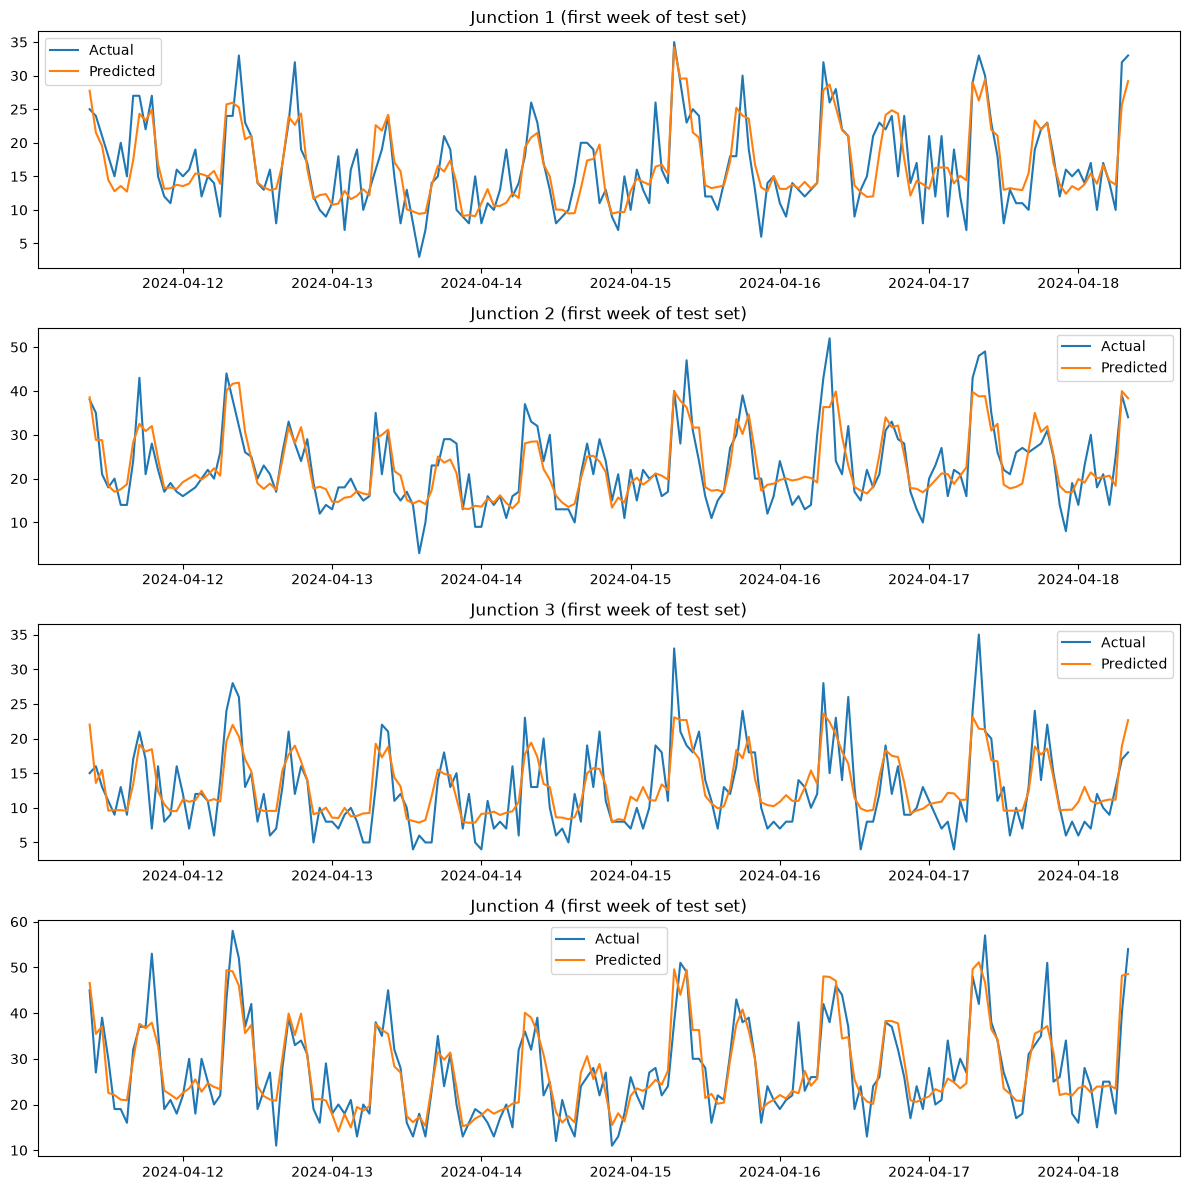

In [4]:
clean_df, _ = pp.clean(pp.load_raw())
features = pp.build_features(clean_df)
fig, axes = plt.subplots(4,1, figsize=(12,12), sharex=False)
for ax, j in zip(axes, sorted(features.Junction.unique())):
    ev = tm.evaluate_on_test_set(model, features, int(j)).head(24*7)
    ax.plot(ev.DateTime, ev.actual, label='Actual'); ax.plot(ev.DateTime, ev.predicted, label='Predicted')
    ax.set_title(f'Junction {j} (first week of test set)'); ax.legend()
plt.tight_layout(); plt.show()

## Residuals

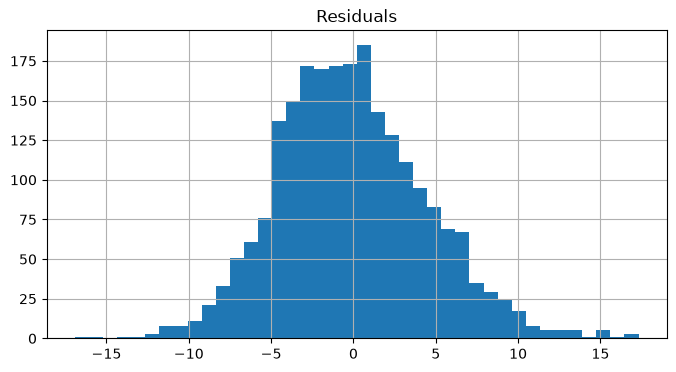

In [5]:
ev = pd.concat([tm.evaluate_on_test_set(model, features, int(j)) for j in features.Junction.unique()])
(ev.actual - ev.predicted).hist(bins=40, figsize=(8,4)); plt.title('Residuals'); plt.show()

## 24-hour forecast example

In [6]:
tm.forecast(model, clean_df, junction=1, horizon=24).head()

,DateTime,predicted
0,2024-05-05 00:00:00,11.260535
1,2024-05-05 01:00:00,10.674739
2,2024-05-05 02:00:00,11.285436
3,2024-05-05 03:00:00,10.606424
4,2024-05-05 04:00:00,10.844695
